In [ ]:
# %pip install pandas numpy matplotlib openpyxl statsmodels
%pip install scikit-learn

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
# import statsmodels.formula.api as smf

In [ ]:
df = pd.read_excel('BD_depresion.xlsx', engine='openpyxl')

# Limpiar nombres de cols
df.columns = (
    df.columns.astype(str)
    .str.strip()
    .str.lower()
    .str.replace(' ', '_')
    .str.replace('á', 'a')
    .str.replace('é', 'e')
    .str.replace('í', 'i')
    .str.replace('ó', 'o')
    .str.replace('ú', 'u')
)

# Corregir posible variante del nombre de estrés
df = df.rename(columns={'estress': 'estres'})

# Normalizar nombres a minuscula
df.columns = df.columns.str.strip().str.lower()

print("\n Cols:", df.columns.tolist())
print("\n Datos importados:", df.shape)
print("\n",df.head(), "\n\n\n")

''' Se acomodan los nombres de las cols.                           
    Se convierten las variables numéricas.
    Se eliminan las filas con valores ausentes.
    Se comprueba q depresion y hco_familiar estén codificadas bien.'''




 Cols: ['id', 'depresion', 'estres', 'apoyo_social', 'autoestima', 'horas_sueno', 'hco_familiar', 'cafeina', 'sexo', 'edad']

 Datos importados: (200, 10)

    id  depresion  estres  apoyo_social  autoestima  horas_sueno  hco_familiar  \
0   1          0     1.8           4.7         2.0          9.4             0   
1   2          1     8.7           2.4         4.0          6.0             0   
2   3          1     8.9           4.4         1.1          8.4             0   
3   4          0     8.1           1.2         9.2          7.4             0   
4   5          0     5.7           5.3         8.4          7.8             0   

   cafeina  sexo  edad  
0      3.2     0    35  
1      0.0     1    39  
2      0.3     1    23  
3      5.0     0    26  
4      5.8     1    39   





In [13]:
print(df.info)

<bound method DataFrame.info of       id  depresion  estres  apoyo_social  autoestima  horas_sueno  \
0      1          0     1.8           4.7         2.0          9.4   
1      2          1     8.7           2.4         4.0          6.0   
2      3          1     8.9           4.4         1.1          8.4   
3      4          0     8.1           1.2         9.2          7.4   
4      5          0     5.7           5.3         8.4          7.8   
..   ...        ...     ...           ...         ...          ...   
195  196          1     5.5           4.4         4.2          6.1   
196  197          0     1.7           5.7         5.8          5.9   
197  198          1     4.1           1.3         4.7          8.4   
198  199          0     7.9           4.3         8.3          6.9   
199  200          0     3.5           3.1         7.9          9.6   

     hco_familiar  cafeina  sexo  edad  
0               0      3.2     0    35  
1               0      0.0     1    39  
2   

In [ ]:

print(df.isnull())  # viene limpio de NaN

        id  depresion  estres  apoyo_social  autoestima  horas_sueno  \
0    False      False   False         False       False        False   
1    False      False   False         False       False        False   
2    False      False   False         False       False        False   
3    False      False   False         False       False        False   
4    False      False   False         False       False        False   
..     ...        ...     ...           ...         ...          ...   
195  False      False   False         False       False        False   
196  False      False   False         False       False        False   
197  False      False   False         False       False        False   
198  False      False   False         False       False        False   
199  False      False   False         False       False        False   

     hco_familiar  cafeina   sexo   edad  
0           False    False  False  False  
1           False    False  False  False  
2     

In [ ]:
vbles = ['depresion','estres','horas_sueno','apoyo_social','autoestima','hco_familiar','cafeina','sexo','edad']

# Comprobar si faltan cols (vbles) en el Excel
faltantes = [v for v in vbles if v not in df.columns]

if faltantes:
    raise ValueError(f"Faltan cols: {faltantes}")

df = df[vbles].copy()

# Convertir vbles numéricas
numericas = ['depresion', 'estres', 'horas_sueno','apoyo_social', 'autoestima','hco_familiar', 'cafeina', 'edad']

# convertir las cols de Excel a formato num. 
for col in numericas:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# limpiar y homogeneizar los valores de la vble sexo del Excel. strip: elimina los espacios en blanco al principio y al final y capitalize pone la 1º letra en may.
df['sexo'] = df['sexo'].astype(str).str.strip().str.capitalize()

df = df.dropna().copy()  # aunq estaban bien desde el ppio, elimina filas y cols con datos (NaN)

# Comprobar vble dependiente, unique coge los valores != de la col, set convierte esos valores en un conjunto sin duplicados. issubset ve si todos los valores pertenecen al {0, 1}.
if not set(df['depresion'].unique()).issubset({0, 1}):   
    raise ValueError("Depresion debe estar codificada como 0 y 1.")

if df['depresion'].nunique() != 2:
    raise ValueError("Se necesitan casos con depresión=0 y depresión=1.")

if not set(df['hco_familiar'].unique()).issubset({0, 1}):
    raise ValueError("hco_familiar debe estar codificada como 0 y 1.")

print("Participantes analizados:", len(df))
print(df['depresion'].value_counts())

Participantes analizados: 200
depresion
0    103
1     97
Name: count, dtype: int64


In [28]:
# Regresion logistica binaria: Contrasto las 2 hipótesis conjuntamente y ajusto por las variables confusoras.

formula = ('depresion ~ estres + horas_sueno + apoyo_social + autoestima + hco_familiar + cafeina + sexo + edad')
modelo = smf.logit(formula=formula, data=df).fit(method='bfgs', maxiter=1000, disp=False)

print(modelo.summary(), "\nConvergencia:", modelo.mle_retvals['converged'])


                           Logit Regression Results                           
Dep. Variable:              depresion   No. Observations:                  200
Model:                          Logit   Df Residuals:                      191
Method:                           MLE   Df Model:                            8
Date:                Thu, 12 Nov 2026   Pseudo R-squ.:                  0.6476
Time:                        17:17:27   Log-Likelihood:                -48.825
converged:                       True   LL-Null:                       -138.54
Covariance Type:            nonrobust   LLR p-value:                 1.356e-34
                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept        1.8989      1.639      1.159      0.247      -1.313       5.111
sexo[T.1]        0.8738      0.554      1.579      0.114      -0.211       1.959
estres           1.1755      0.194      6.05

In [ ]:
# Calcular OR, IC 95 % y valores p

params = modelo.params
conf = modelo.conf_int()

rdos = pd.DataFrame({
    'Coeficiente': params,
    'Odds_Ratio': np.exp(params),
    'IC_95%_inferior': np.exp(conf[0]),  # converierte el límite inferior del intervalo del coeficiente de regresión logística en el límite inferior del intervalo Ratio (OR).
    'IC_95%_superior': np.exp(conf[1]),
    'p_valor': modelo.pvalues
})

print("\nRDOS REGRESIÓN LOGÍSTICA")
print(rdos.round(3))


RDOS REGRESIÓN LOGÍSTICA
              Coeficiente  Odds_Ratio  IC_95%_inferior  IC_95%_superior  \
Intercept           1.899       6.678            0.269          165.789   
sexo[T.1]           0.874       2.396            0.810            7.090   
estres              1.176       3.240            2.214            4.741   
horas_sueno        -0.409       0.664            0.471            0.938   
apoyo_social       -0.841       0.431            0.321            0.580   
autoestima         -0.892       0.410            0.298            0.563   
hco_familiar        1.739       5.691            1.762           18.388   
cafeina             0.101       1.106            0.803            1.524   
edad                0.049       1.050            1.008            1.094   

              p_valor  
Intercept       0.247  
sexo[T.1]       0.114  
estres          0.000  
horas_sueno     0.020  
apoyo_social    0.000  
autoestima      0.000  
hco_familiar    0.004  
cafeina         0.536  
edad   

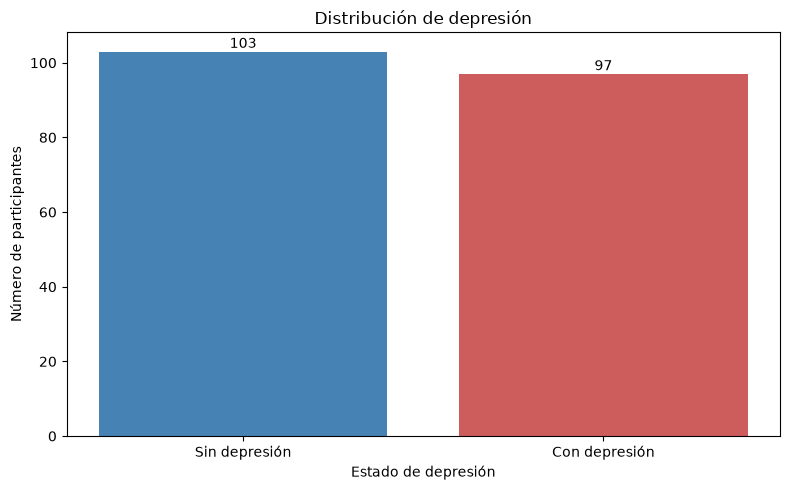

In [8]:
# Gráfico 1: distribución de depresión

frecuencias = df['depresion'].value_counts().sort_index()

plt.figure(figsize=(8, 5))

plt.bar(
    ['Sin depresión', 'Con depresión'],
    frecuencias.values,
    color=['steelblue', 'indianred']
)

plt.title('Distribución de depresión')
plt.ylabel('Número de participantes')
plt.xlabel('Estado de depresión')

for i, valor in enumerate(frecuencias.values):
    plt.text(i, valor + 1, str(valor), ha='center')

plt.tight_layout()
plt.show()

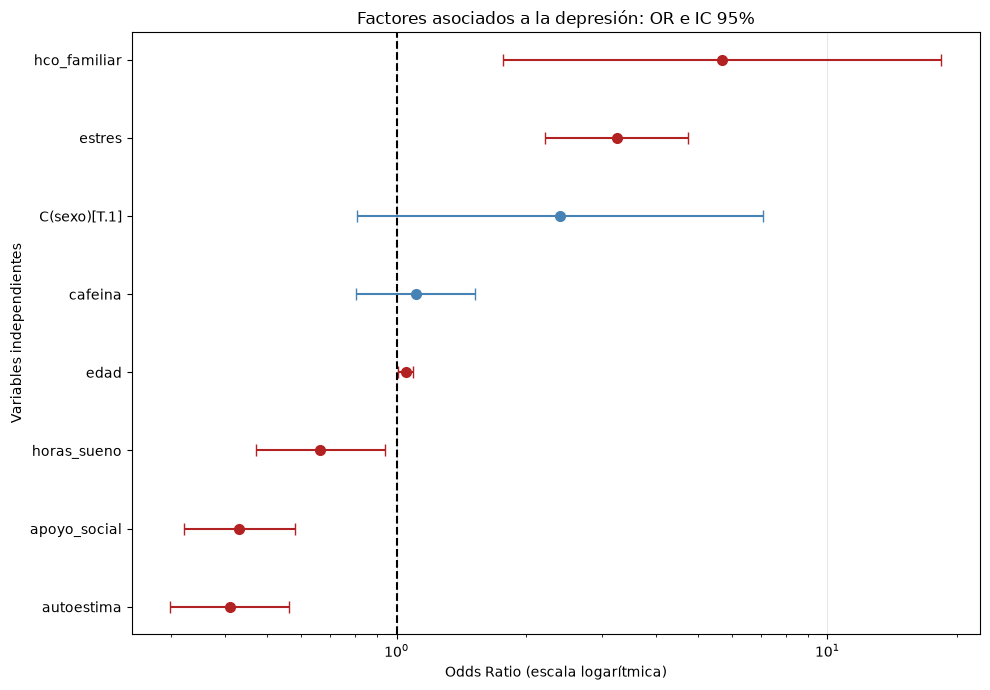

In [9]:
#  Gráfico 2: Odds Ratios de todas las variables

grafico = rdos.drop(
    index='Intercept',
    errors='ignore'
).sort_values('Odds_Ratio')

plt.figure(figsize=(10, 7))

for i, (variable, fila) in enumerate(grafico.iterrows()):

    color = 'firebrick' if fila['p_valor'] < 0.05 else 'steelblue'

    plt.errorbar(
        fila['Odds_Ratio'],
        i,
        xerr=[[
            fila['Odds_Ratio'] - fila['IC_95%_inferior']
        ], [
            fila['IC_95%_superior'] - fila['Odds_Ratio']
        ]],
        fmt='o',
        color=color,
        capsize=4,
        markersize=7
    )

plt.axvline(1, color='black', linestyle='--')

plt.xscale('log')
plt.yticks(range(len(grafico)), grafico.index)

plt.xlabel('Odds Ratio (escala logarítmica)')
plt.ylabel('Variables independientes')
plt.title('Factores asociados a la depresión: OR e IC 95%')

plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

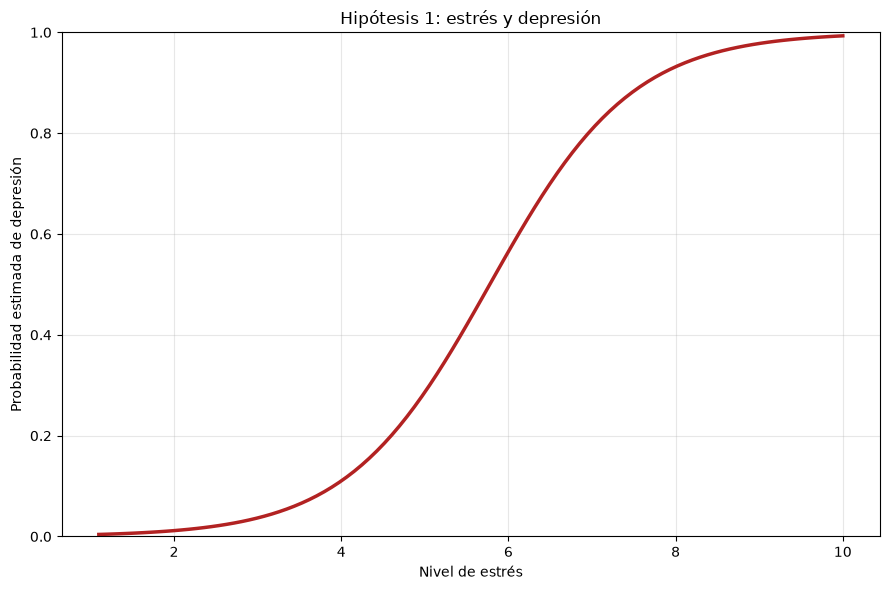

In [10]:
# Gráfico 3: hipótesis 1 – estrés  -->   Representa cómo cambia la probabilidad estimada de depresión a medida que aumenta el estrés.

estres_grid = np.linspace(df['estres'].min(), df['estres'].max(), 100)

# Mantener constantes las demás variables
base = {
    'horas_sueno': df['horas_sueno'].median(),
    'apoyo_social': df['apoyo_social'].median(),
    'autoestima': df['autoestima'].median(),
    'hco_familiar': df['hco_familiar'].mode()[0],
    'cafeina': df['cafeina'].median(),
    'sexo': df['sexo'].mode()[0],
    'edad': df['edad'].median()
}

pred_stress = pd.DataFrame({ **{k: [v] * len(estres_grid) for k, v in base.items()}, 'estres': estres_grid})
prob_estres = modelo.predict(pred_stress)
plt.figure(figsize=(9, 6))

plt.plot( estres_grid, prob_estres, color='firebrick', linewidth=2.5)

plt.xlabel('Nivel de estrés')
plt.ylabel('Probabilidad estimada de depresión')
plt.title('Hipótesis 1: estrés y depresión')

plt.ylim(0, 1)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

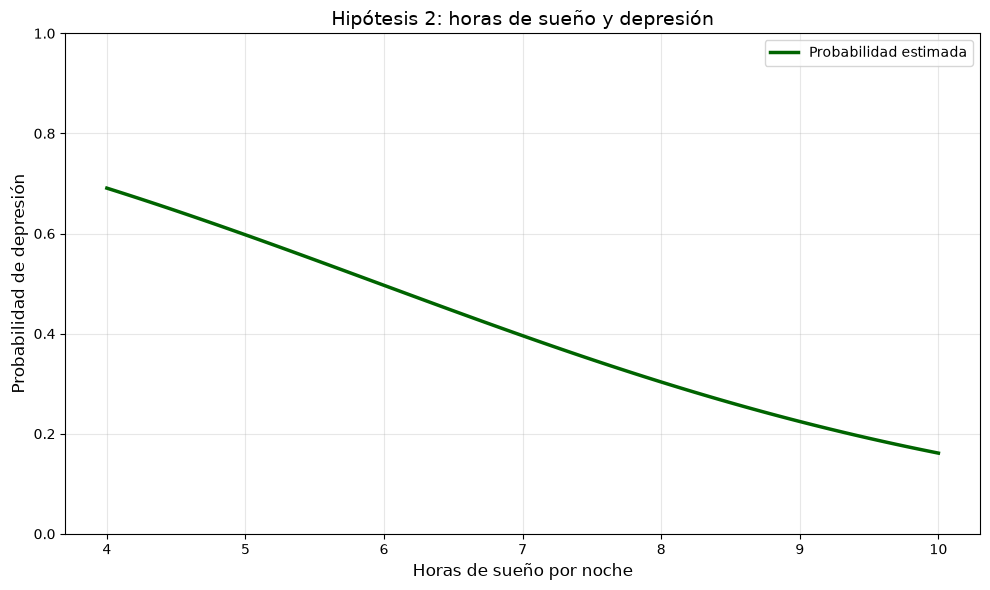

In [ ]:
# Gráfico 4: hipótesis 2 – horas de sueño

# 1. Crear valores de horas de sueño
sueno_grid = np.linspace(df['horas_sueno'].min(), df['horas_sueno'].max(), 100)

# 2. Identificar las categorías originales de sexo
sexo_modelo = modelo.model.data.frame['sexo'].mode()[0]

# 3. Crear base de predicción
pred_sueno = pd.DataFrame({
    'estres': [df['estres'].median()] * 100,
    'horas_sueno': sueno_grid,
    'apoyo_social': [df['apoyo_social'].median()] * 100,
    'autoestima': [df['autoestima'].median()] * 100,
    'hco_familiar': [df['hco_familiar'].mode()[0]] * 100,
    'cafeina': [df['cafeina'].median()] * 100,
    'sexo': [sexo_modelo] * 100,
    'edad': [df['edad'].median()] * 100
})

# 4. Calcular probabilidades estimadas
prob_sueno = modelo.predict(pred_sueno)

# 5. Representar el gráfico
plt.figure(figsize=(10, 6))
plt.plot( sueno_grid, prob_sueno, color='darkgreen', linewidth=2.5, label='Probabilidad estimada')
plt.xlabel('Horas de sueño por noche', fontsize=12)
plt.ylabel('Probabilidad de depresión', fontsize=12)
plt.title('Hipótesis 2: horas de sueño y depresión', fontsize=14)

plt.ylim(0, 1)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


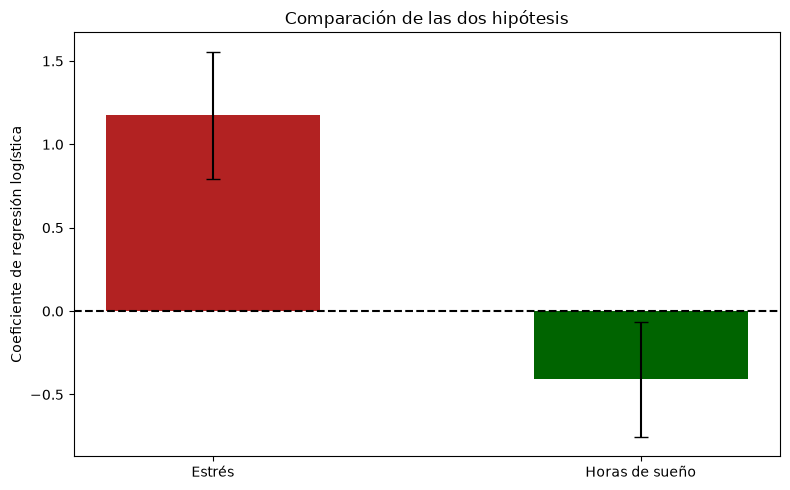

In [ ]:
# Gráfico 5: comparación de los coeficientes de las dos hipótesis  --> comparar la dirección y magnitud de los coeficientes logísticos

variables_hipotesis = ['estres', 'horas_sueno']
coef = modelo.params[variables_hipotesis]
errores = modelo.bse[variables_hipotesis]
plt.figure(figsize=(8, 5))
colores = ['firebrick', 'darkgreen']

plt.bar( ['Estrés', 'Horas de sueño'], coef.values, color=colores, width=0.5)
plt.errorbar(['Estrés', 'Horas de sueño'], coef.values, yerr=1.96 * errores.values, fmt='none', color='black', capsize=5)
plt.axhline(0, color='black', linestyle='--')
plt.ylabel('Coeficiente de regresión logística')
plt.title('Comparación de las dos hipótesis')

plt.tight_layout()
plt.show()


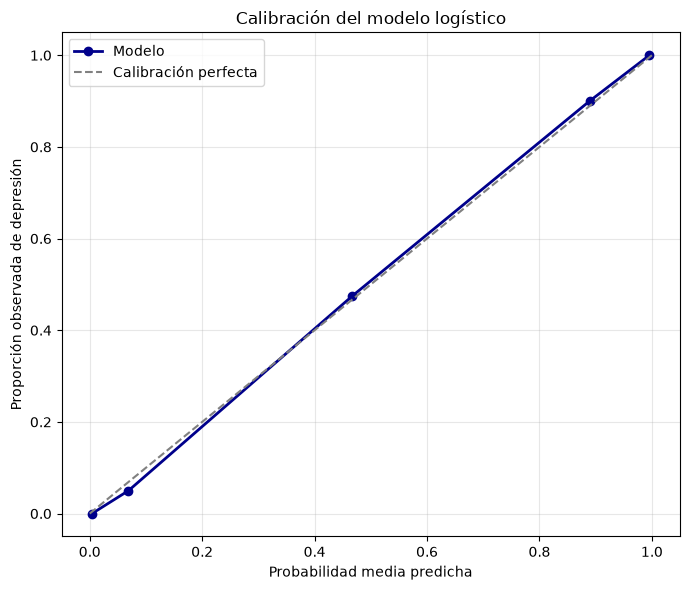

In [14]:
# Gráfico 6: probabilidad estimada frente a observada --> compara la frecuencia de depresión con las probabilidades estimadas por el modelo.

probabilidades = modelo.predict(df)
datos_calibracion = pd.DataFrame({ 'probabilidad': probabilidades, 'depresion': df['depresion']})
datos_calibracion['grupo'] = pd.qcut( datos_calibracion['probabilidad'], q=5, duplicates='drop')
calibracion = datos_calibracion.groupby('grupo', observed=True).agg(probabilidad_media=('probabilidad', 'mean'),depresion_observada=('depresion', 'mean'))

plt.figure(figsize=(7, 6))

plt.plot(calibracion['probabilidad_media'], calibracion['depresion_observada'], marker='o', color='darkblue', linewidth=2,label='Modelo')

plt.plot([0, 1],[0, 1], linestyle='--', color='gray', label='Calibración perfecta')

plt.xlabel('Probabilidad media predicha')
plt.ylabel('Proporción observada de depresión')
plt.title('Calibración del modelo logístico')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [15]:
# Explotar Cod.

with pd.ExcelWriter('Rdos_depresion.xlsx', engine='openpyxl') as writer:

    rdos.round(4).to_excel( writer, sheet_name='Odds_Ratios')
    df.to_excel( writer,sheet_name='Datos_analizados', index=False)
    calibracion.to_excel( writer, sheet_name='Calibracion')

print("Análisis finalizado.")
print("Archivo Rdos_depresion.xlsx creado.")

Análisis finalizado.
Archivo Rdos_depresion.xlsx creado.


Interpretación hipótesis: al tener los rdos reales, uso esta tabla:

Criterio                    Hipótesis 1: estrés      Hipótesis 2: sueño
Dirección esperada del OR    OR > 1                    OR < 1
Valor p                      p < 0,05                  p < 0,05
IC 95 %                      No incluye 1              No incluye 1
Interpretación      Factor de riesgo asociado       Factor protector asociado

Imp: un OR de 1,35 supone un aumento del 35 % en las odds, no necesariamente en la probabilidad. Un OR de 0,78 supone una reducción del 22 % en las odds.

Además, los gráficos de probabilidad representan asociaciones ajustadas, no efectos causales. Para evaluar la capacidad predictiva real, habría que validar el modelo con datos que no se hayan utilizado para ajustarlo.


Gráficos:

Odds Ratios con IC del 95 %
Es el gráfico más importante para presentar los factores asociados a la depresión.
Gráfico de estrés
Para explicar visualmente la primera hipótesis.
Gráfico de horas de sueño
Para explicar visualmente la segunda hipótesis.
Calibración del modelo
Para evaluar visualmente la concordancia entre probabilidades predichas y observadas.